# Pressing in StatsBomb Open Data

Follow a press from the event and 360 freeze frame through the 26 SPN inputs to its predicted outcome. A second score compares an individual presser’s observed position with feasible alternatives. The saved results cover all 64 matches of the 2022 FIFA World Cup, from the group stage through the final. The frame and feature tables illustrate one sequence. The rankings combine all selected fixtures.

## Select matches · StatsBomb Open Data

The default, `MATCH_IDS = None`, selects every match with event and 360 coverage in the chosen competition and season. Set it to a list of match IDs for a smaller run. Event and 360 records are saved under `output/sample/`. [Data supplied by StatsBomb](https://github.com/statsbomb/open-data) · [Notebook installation](../README.md#sample-workflow)

In [1]:
from pathlib import Path
import json
import sys
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display
from statsbombpy import sb
from statsbombpy.api_client import NoAuthWarning

COMPETITION_ID, SEASON_ID = 43, 106
MATCH_IDS = None

root = Path.cwd()
if root.name == "tests":
    root = root.parent
sys.path.insert(0, str(root))
sample_dir = root / "output" / "sample"
events_dir = sample_dir / "events"
frames_dir = sample_dir / "three-sixty"
matches_dir = sample_dir / "matches"
for directory in (events_dir, frames_dir, matches_dir):
    directory.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=NoAuthWarning)
catalogue = sb.matches(COMPETITION_ID, SEASON_ID, fmt="dict", creds={})
available = {i: m for i, m in catalogue.items()
             if m.get("match_status") == m.get("match_status_360") == "available"}
if MATCH_IDS is None:
    selected = sorted(available, key=lambda i: (available[i]["match_date"], available[i].get("kick_off") or "", i))
else:
    selected = list(dict.fromkeys(MATCH_IDS))
if not selected:
    raise ValueError("Select at least one match with event and 360 coverage.")
unavailable = set(selected) - available.keys()
if unavailable:
    raise ValueError(f"These matches lack paired data in the selected season: {sorted(unavailable)}")

fixtures = {str(i): available[i] for i in selected}
fixture_table = pd.DataFrame([
    {"match_id": mid, "date": m["match_date"], "home": m["home_team"]["home_team_name"],
     "away": m["away_team"]["away_team_name"], "stage": m["competition_stage"]["name"],
     "events": m["match_status"], "360": m["match_status_360"]}
    for mid, m in fixtures.items()
]).set_index("match_id")
print(f"Selected {len(fixtures)} of {len(catalogue)} fixtures. Event and 360 data available for {len(available)}.")
display(fixture_table.groupby("stage", sort=False).size().rename("matches").to_frame())
display(fixture_table)

for mid in fixtures:
    events = list(sb.events(match_id=int(mid), fmt="dict", creds={}).values())
    frames = sb.frames(match_id=int(mid), fmt="dict", creds={})
    (events_dir / f"{mid}.json").write_text(json.dumps(events), encoding="utf-8")
    (frames_dir / f"{mid}.json").write_text(json.dumps(frames), encoding="utf-8")

Selected 64 of 64 fixtures. Event and 360 data available for 64.


,matches
stage,
Group Stage,48
Round of 16,8
Quarter-finals,4
Semi-finals,2
3rd Place Final,1
Final,1


,date,home,away,stage,events,360
match_id,,,,,,
3857286,2022-11-20,Qatar,Ecuador,Group Stage,available,available
3857271,2022-11-21,England,Iran,Group Stage,available,available
3857285,2022-11-21,Senegal,Netherlands,Group Stage,available,available
3857282,2022-11-21,United States,Wales,Group Stage,available,available
3857300,2022-11-22,Argentina,Saudi Arabia,Group Stage,available,available
...,...,...,...,...,...,...
3869354,2022-12-10,England,France,Quarter-finals,available,available
3869519,2022-12-13,Argentina,Croatia,Semi-finals,available,available
3869552,2022-12-14,France,Morocco,Semi-finals,available,available


## Read the match and label pressure sequences · `spn.data_processing`

An **anchor** is a ball-side event at which SPN detects high pressure. Consecutive anchors can belong to one sequence. Read the example down the rows to see when the press continued, how it ended and which outcome the pressing team received. Times are relative to the period.

In [2]:
from spn.data_processing import LabelConfig, SequenceConfig, build_sequences_from_match, load_match_data
from spn.model import SPNModel
from spn.networks import PressureParams

model = SPNModel()
params = PressureParams(**model.config["pressure"])
sequence_config = SequenceConfig(**model.config["sequence"])
label_config = LabelConfig(**model.config["labels"])

def read_match(mid):
    return load_match_data(events_dir / f"{mid}.json", frames_dir / f"{mid}.json", match_id=mid)

anchors, labels, counts = {}, {}, []
for mid in fixtures:
    match = read_match(mid)
    anchors[mid], labels[mid] = build_sequences_from_match(match, sequence_config, params, label_config)
    counts.append({"match_id": mid, "events": len(match.events), "usable_frames": len(match.frames),
                   "anchors": len(anchors[mid]), "sequences": anchors[mid].seq_id.nunique()})
display(pd.DataFrame(counts).set_index("match_id"))

all_labels = pd.concat(labels.values(), ignore_index=True)
onsets = all_labels.loc[all_labels.is_onset.eq(True) & all_labels.value_model_eligible.eq(True)]
multiple = onsets.loc[onsets.anchor_count.gt(1)]
example = (multiple if not multiple.empty else onsets).head(1)

def example_rows(table):
    keys = ["match_id", "seq_id"]
    return table.merge(example[keys], on=keys).sort_values("ev_pos")

display(example_rows(all_labels)[["match_id", "seq_id", "ev_pos", "period", "timestamp", "event_type",
                                 "press_team_name", "state", "outcome_tag"]])

,events,usable_frames,anchors,sequences
match_id,,,,
3857286,3299,3073,262,136
3857271,3649,3303,244,119
3857285,3133,2632,164,91
3857282,3687,3299,272,133
3857300,3329,2854,168,94
...,...,...,...,...
3869354,3239,2749,217,104
3869519,3806,3127,239,109
3869552,3551,2926,219,111


,match_id,seq_id,ev_pos,period,timestamp,event_type,press_team_name,state,outcome_tag
0,3857286,1,0,1,00:00:07.177,Pass,Qatar,continued_pressure,success
1,3857286,1,1,1,00:00:08.184,Pass,Qatar,continued_pressure,success
2,3857286,1,2,1,00:00:11.060,Pass,Qatar,continued_pressure,success
3,3857286,1,3,1,00:00:12.421,Carry,Qatar,continued_pressure,success
4,3857286,1,4,1,00:00:13.460,Pass,Qatar,continued_pressure,success
5,3857286,1,5,1,00:00:14.748,Pass,Qatar,regain_control,success


## Inspect one freeze frame · `spn.networks`

At the first anchor of the example sequence, a pressure edge links a defender to a target. A passing option links the carrier to a visible teammate. The network below includes the carrier’s location in metres on the 105 × 68 m pitch.

In [3]:
from spn.networks import build_spn_network

if example.empty:
    print("No resolved sequence to illustrate in this selection.")
else:
    onset = example.iloc[0]
    match = read_match(onset.match_id)
    event = match.events[int(onset.raw_event_position)]
    try:
        network = build_spn_network(event, match.frames[onset.anchor_event_id], params)
    except ValueError as error:
        print(f"This anchor has no usable network: {error}")
    else:
        x, y = network["xy"][network["carrier"]]
        display(pd.DataFrame([{
            "anchor_event_id": onset.anchor_event_id, "carrier": event.get("player", {}).get("name"),
            "x_m": x, "y_m": y, "defenders": len(network["defenders"]),
            "pressure_edges": len(network["pressure_edges"]), "passing_options": len(network["passes"]),
        }]))

,anchor_event_id,carrier,x_m,y_m,defenders,pressure_edges,passing_options
0,d5882e10-588d-49a3-a1cb-784f0debf0c5,Piero Martín Hincapié Reyna,12.6,32.13,3,5,5


## Measure the 26 inputs · `spn.feature_engineering`

A sequence enters the model when its outcome is resolved and every anchor has a usable network. The first table counts the exclusions. The second shows the 26 values at the example onset, in model order. Missing geometry or context stays missing. [Feature definitions and units](../spn/MODEL.md)

In [4]:
from spn.feature_engineering import build_feature_table

features = {mid: build_feature_table(read_match(mid), anchors[mid], labels[mid], params=params)
            for mid in fixtures}
audit = pd.DataFrame({mid: table.attrs["s3_completeness_audit"] for mid, table in features.items()}).T
display(audit.rename_axis("match_id"))

example_features = example_rows(pd.concat(features.values(), ignore_index=True))
if example_features.empty:
    print("The selection has no scored anchor for the illustrated sequence.")
else:
    values = example_features.iloc[0][model.features]
    display(values.rename("value at onset").rename_axis("feature").to_frame())

,expected_anchors,expected_sequences,retained_anchors,excluded_incomplete_sequences,excluded_censored_sequences
match_id,,,,,
3857286,262,136,254,0,2
3857271,244,119,244,0,0
3857285,164,91,159,0,1
3857282,272,133,267,0,3
3857300,168,94,160,0,6
...,...,...,...,...,...
3869354,217,104,210,0,4
3869519,239,109,226,0,4
3869552,219,111,217,0,1


,value at onset
feature,
ball_in_dist,3.073098
ball_in_angle_cos,0.996551
carrier_x_norm,0.12
d_carrier_x_norm_dt,NaN
carrier_touchline_m,32.13
P_total,0.941502
d_P_total_dt,NaN
effective_pressers,1.0
n_open_pass,2


## Predict the outcome at each anchor · `spn.model`

Each row estimates how the sequence will end for the pressing team, using information through that anchor. Compare the three calibrated probabilities down the sequence. The rule-derived outcome alongside them is observed later.

In [5]:
predictions = {mid: model.predict(table) for mid, table in features.items()}
print(f"{sum(len(table) for table in predictions.values()):,} anchor predictions across {len(fixtures)} matches.")
example_predictions = example_rows(pd.concat(predictions.values(), ignore_index=True))
display(example_predictions.merge(
    example_features[["anchor_event_id", "timestamp", "event_type", "outcome_tag"]],
    on="anchor_event_id", validate="one_to_one",
)[["match_id", "seq_id", "ev_pos", "timestamp", "event_type", "p_fail", "p_neutral",
   "p_success", "predicted_class", "confidence", "outcome_tag"]].round(4))

15,578 anchor predictions across 64 matches.


,match_id,seq_id,ev_pos,timestamp,event_type,p_fail,p_neutral,p_success,predicted_class,confidence,outcome_tag
0,3857286,1,0,00:00:07.177,Pass,0.5793,0.3556,0.0651,fail,0.5793,success
1,3857286,1,1,00:00:08.184,Pass,0.4049,0.3888,0.2063,fail,0.4049,success
2,3857286,1,2,00:00:11.060,Pass,0.3297,0.3510,0.3193,neutral,0.3510,success
3,3857286,1,3,00:00:12.421,Carry,0.4439,0.2034,0.3528,fail,0.4439,success
4,3857286,1,4,00:00:13.460,Pass,0.3880,0.3181,0.2939,fail,0.3880,success
5,3857286,1,5,00:00:14.748,Pass,0.2665,0.4159,0.3177,neutral,0.4159,success


## Score the recorded presser · `spn.positioning`

This task starts from the original match. A scored row requires a named StatsBomb `Pressure` event, an identified carrier and feasible alternative positions under high pressure. The score in percentage points is 100 × (observed five-second regain probability − mean alternative regain probability). A positive value favours the observed position.

In [6]:
from spn.positioning import PositioningModel

position_model = PositioningModel()
pressures, named_scores = {}, []
for mid in fixtures:
    match = read_match(mid)
    pressures[mid] = position_model.predict(match)
    names = {e["id"]: (e.get("player") or {}).get("name") for e in match.events}
    named_scores.append(pressures[mid].assign(player=pressures[mid].event_id.map(names)))

display(pd.Series({mid: len(p) for mid, p in pressures.items()}, name="scored_pressures")
        .rename_axis("match_id").to_frame())
scored_matches = [table for table in named_scores if not table.empty]
position_scores = pd.concat(scored_matches, ignore_index=True) if scored_matches else named_scores[0]
print(f"{len(position_scores):,} recorded pressures scored in {len(scored_matches)} of {len(fixtures)} matches.")
display(position_scores[["match_id", "event_id", "player", "valid_alternatives", "observed_probability",
                         "alternative_probability", "position_quality_pp"]].head(10).round(4))

,scored_pressures
match_id,
3857286,13
3857271,14
3857285,9
3857282,19
3857300,11
...,...
3869354,13
3869519,12
3869552,18


942 recorded pressures scored in 64 of 64 matches.


,match_id,event_id,player,valid_alternatives,observed_probability,alternative_probability,position_quality_pp
0,3857286,9fe86a47-272f-4eba-ac11-b23498691ae2,Pervis Josué Estupiñán Tenorio,64,0.2340,0.2287,0.5281
1,3857286,9a31476b-b2a4-49ec-ae3f-b8e5324f7c53,Moisés Isaac Caicedo Corozo,64,0.1361,0.1367,-0.0627
2,3857286,2405b40d-6b49-4937-a39a-aff14f83c586,Michael Steveen Estrada Martínez,59,0.1741,0.1536,2.0466
3,3857286,5623ea1c-0c90-45ea-b3af-82d8c25fbd99,Enner Remberto Valencia Lastra,63,0.1103,0.1124,-0.2065
4,3857286,20161599-c248-4baf-9711-5dd6cd26a4b8,Michael Steveen Estrada Martínez,64,0.0552,0.0562,-0.0955
5,3857286,27b18216-9f45-4f17-b549-fc9ad5cd3640,Michael Steveen Estrada Martínez,64,0.0937,0.1032,-0.9435
6,3857286,9b5e667a-eb57-408a-a2a0-055263b10c47,Pedro Miguel Correia,64,0.1198,0.1127,0.7111
7,3857286,112936f8-7000-4af4-a611-5e8b8d3ef650,Abdulaziz Hatem Mohammed Abdullah,64,0.1144,0.1219,-0.7525
8,3857286,4dac6e86-a408-4dda-bf7b-02e3e135e2d9,Gonzalo Jordy Plata Jiménez,64,0.1712,0.1719,-0.0708
9,3857286,b21ca04c-ede8-4a41-afc8-041653e543b6,Homam Alamin Ahmed,60,0.1457,0.1601,-1.4431


## Save the match tables and summarise teams · `spn.output`

Each match has a sequence table, anchor predictions, the 26 inputs, presser scores and a team summary. Team press value averages `p_success − p_fail` at sequence onset, giving each scored sequence one vote. The batch index tells the plotter which matches belong to this selection.

In [7]:
from spn.output import build_result, empty_result, save_features, save_result, team_values

batch, team_tables = [], []
for mid in fixtures:
    match = read_match(mid)
    if anchors[mid].empty:
        result = empty_result(match, model)
    else:
        result = build_result(match=match, sequences=anchors[mid], labels=labels[mid],
                              features=features[mid], predictions=predictions[mid], model=model)
    scored = pd.DataFrame(result["predictions"], columns=[
        "match_id", "seq_id", "ev_pos", "pressing_team_id", "p_success", "p_fail",
    ])
    teams = team_values(scored)
    result["teams"] = teams.to_dict("records")
    result["pressures"] = pressures[mid].to_dict("records")
    result["audit"]["position_count"] = len(pressures[mid])

    folder = matches_dir / mid
    save_result(result, folder)
    save_features(features[mid], model, folder)
    teams.to_csv(folder / "teams.csv", index=False)
    pressures[mid].to_csv(folder / "pressures.csv", index=False)
    batch.append({"match_id": mid, "status": result["status"], "prediction_count": len(scored),
                  "position_count": len(pressures[mid])})
    names = {e["team"]["id"]: e["team"]["name"] for e in match.events if e.get("team")}
    team_tables.append(teams.assign(match_id=mid, team=teams.pressing_team_id.map(names)))

(matches_dir / "batch_result.json").write_text(json.dumps(batch, indent=2), encoding="utf-8")
display(pd.concat(team_tables)[["match_id", "team", "presses", "expected_press_value"]].round(4))
print(f"Match tables: {matches_dir.relative_to(root)}")

,match_id,team,presses,expected_press_value
0,3857286,Ecuador,66,-0.2578
1,3857286,Qatar,68,-0.2662
0,3857271,England,29,-0.2863
1,3857271,Iran,90,-0.2570
0,3857285,Senegal,45,-0.2139
...,...,...,...,...
1,3869552,Morocco,49,-0.3078
0,3869684,Croatia,63,-0.2028
1,3869684,Morocco,76,-0.2868
0,3869685,France,88,-0.2350


Match tables: output/sample/matches


## Rank teams and players · `spn.plotting`

The three rankings use all selected fixtures. Counts beside the values show how many scored sequences or pressures contribute to each mean.

### Expected press value by team · FIFA World Cup 2022 · all 64 matches

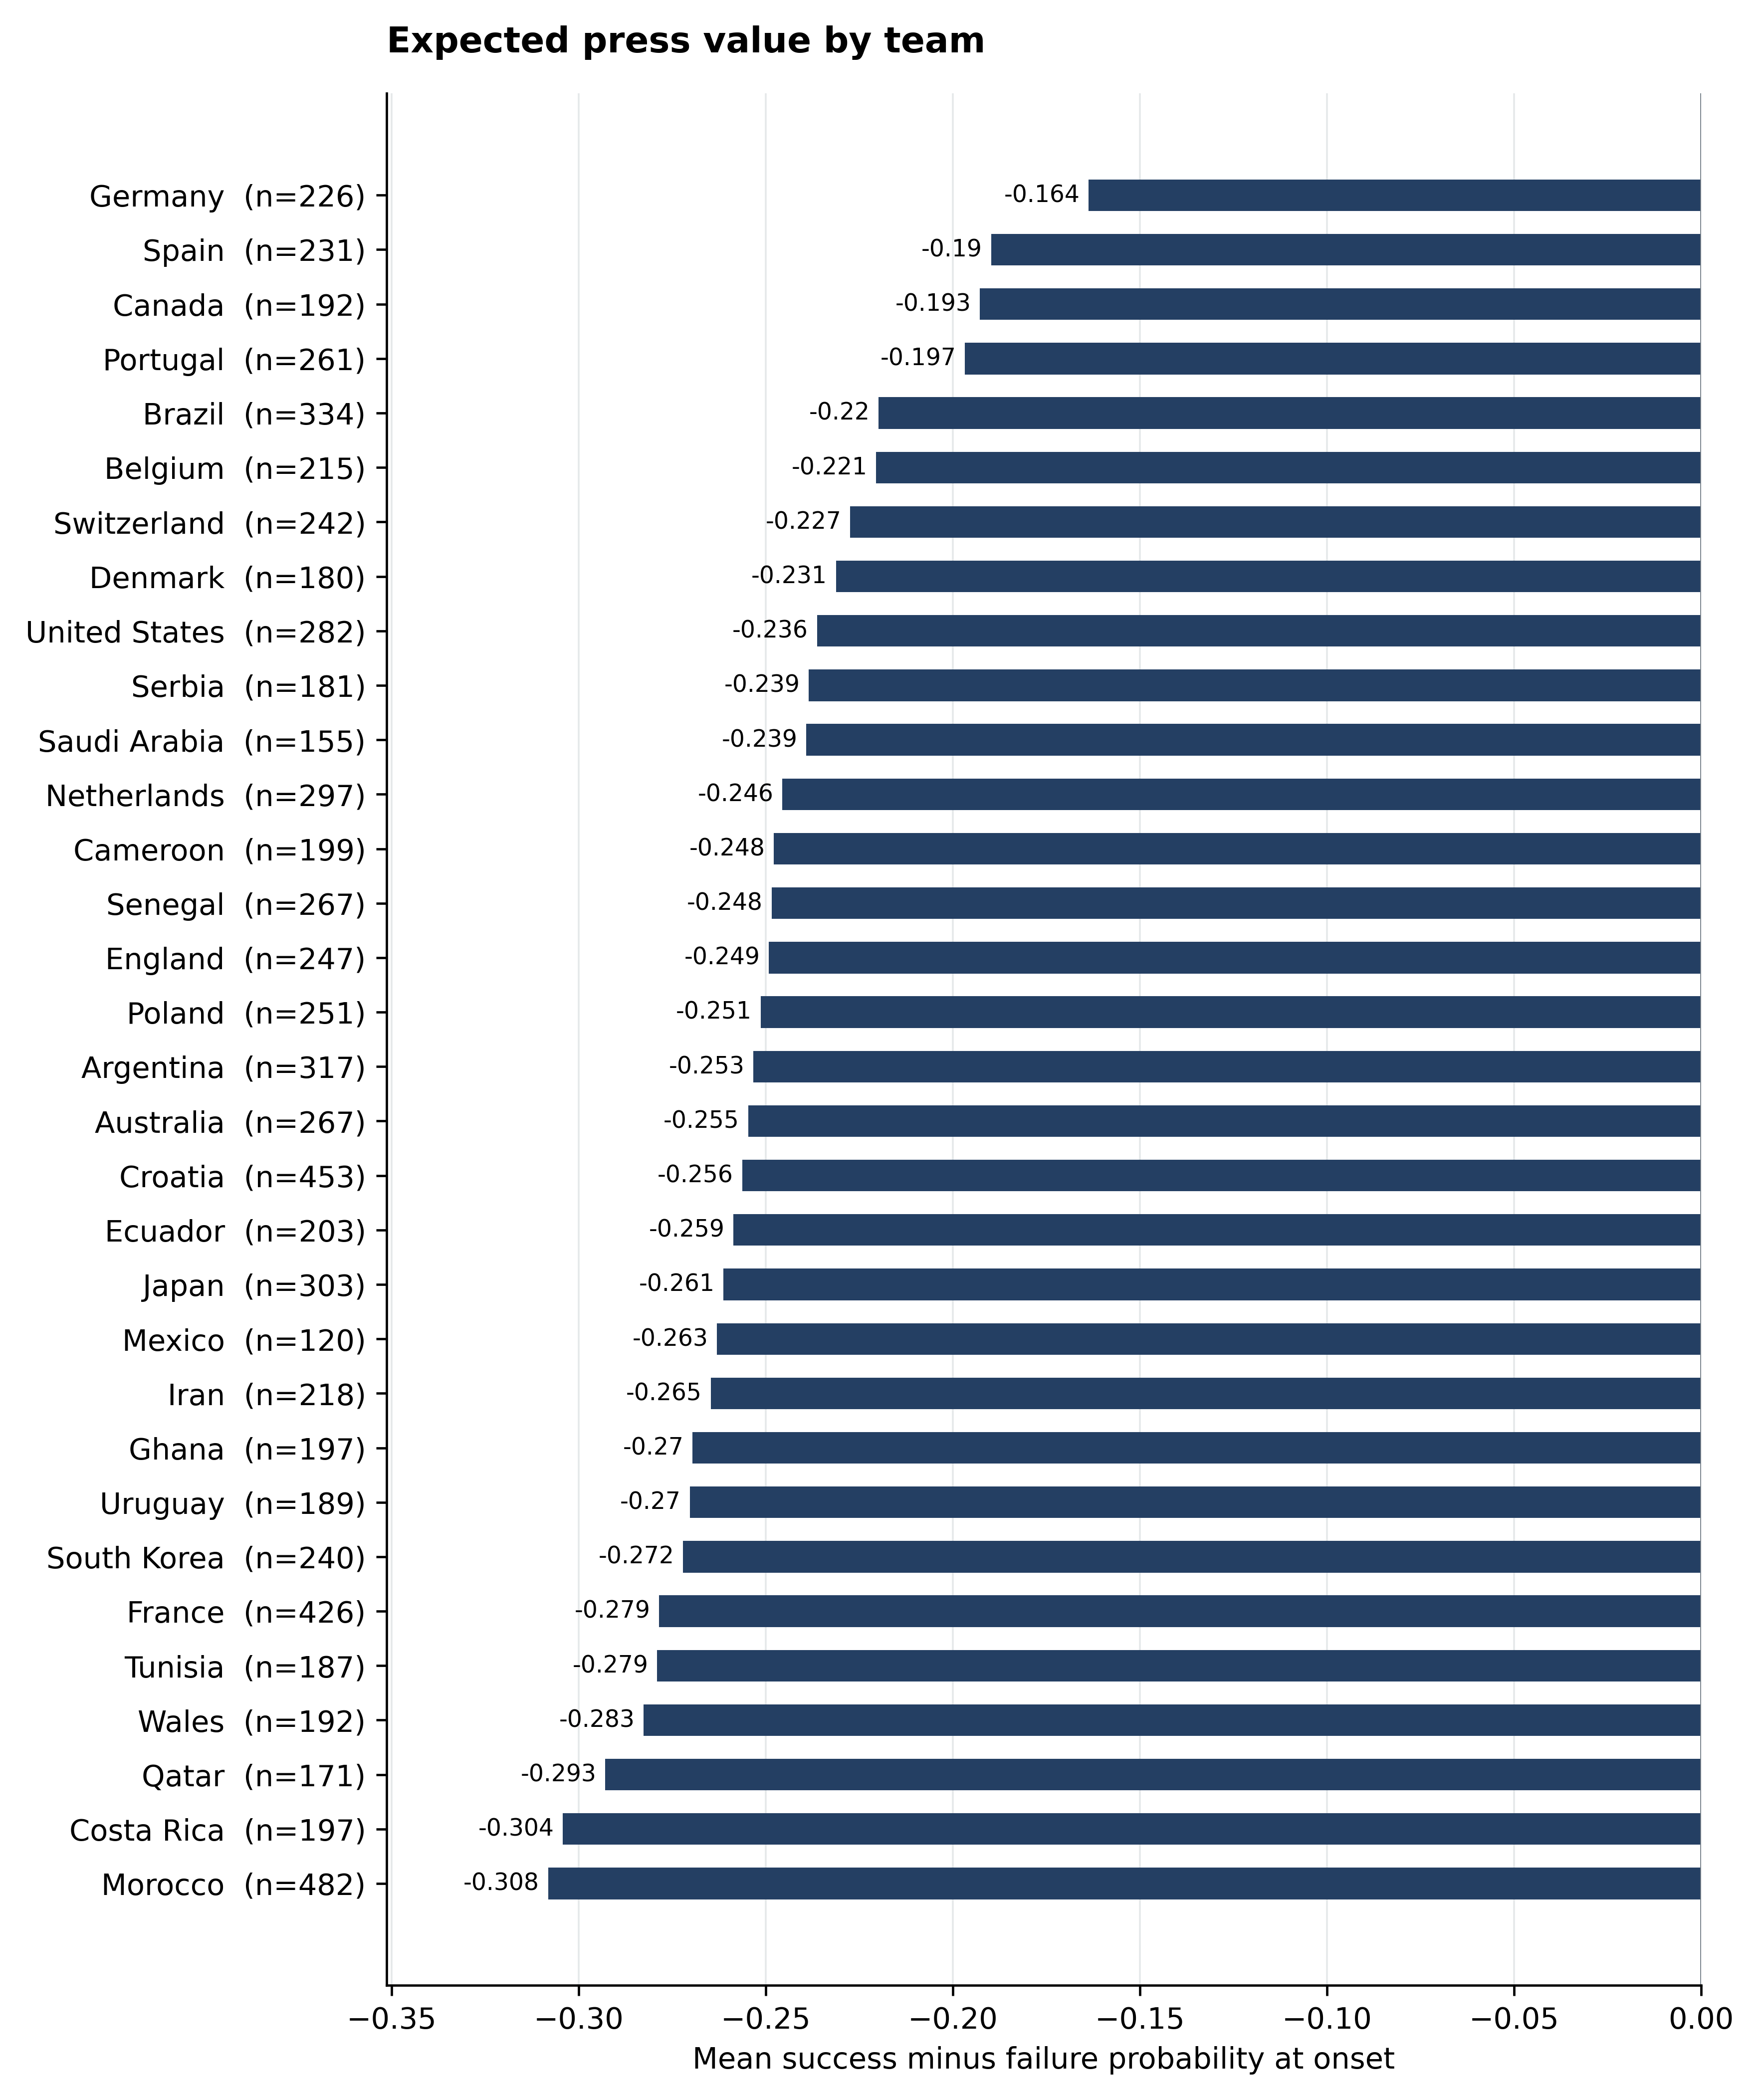

### Presser positioning by team · FIFA World Cup 2022 · all 64 matches

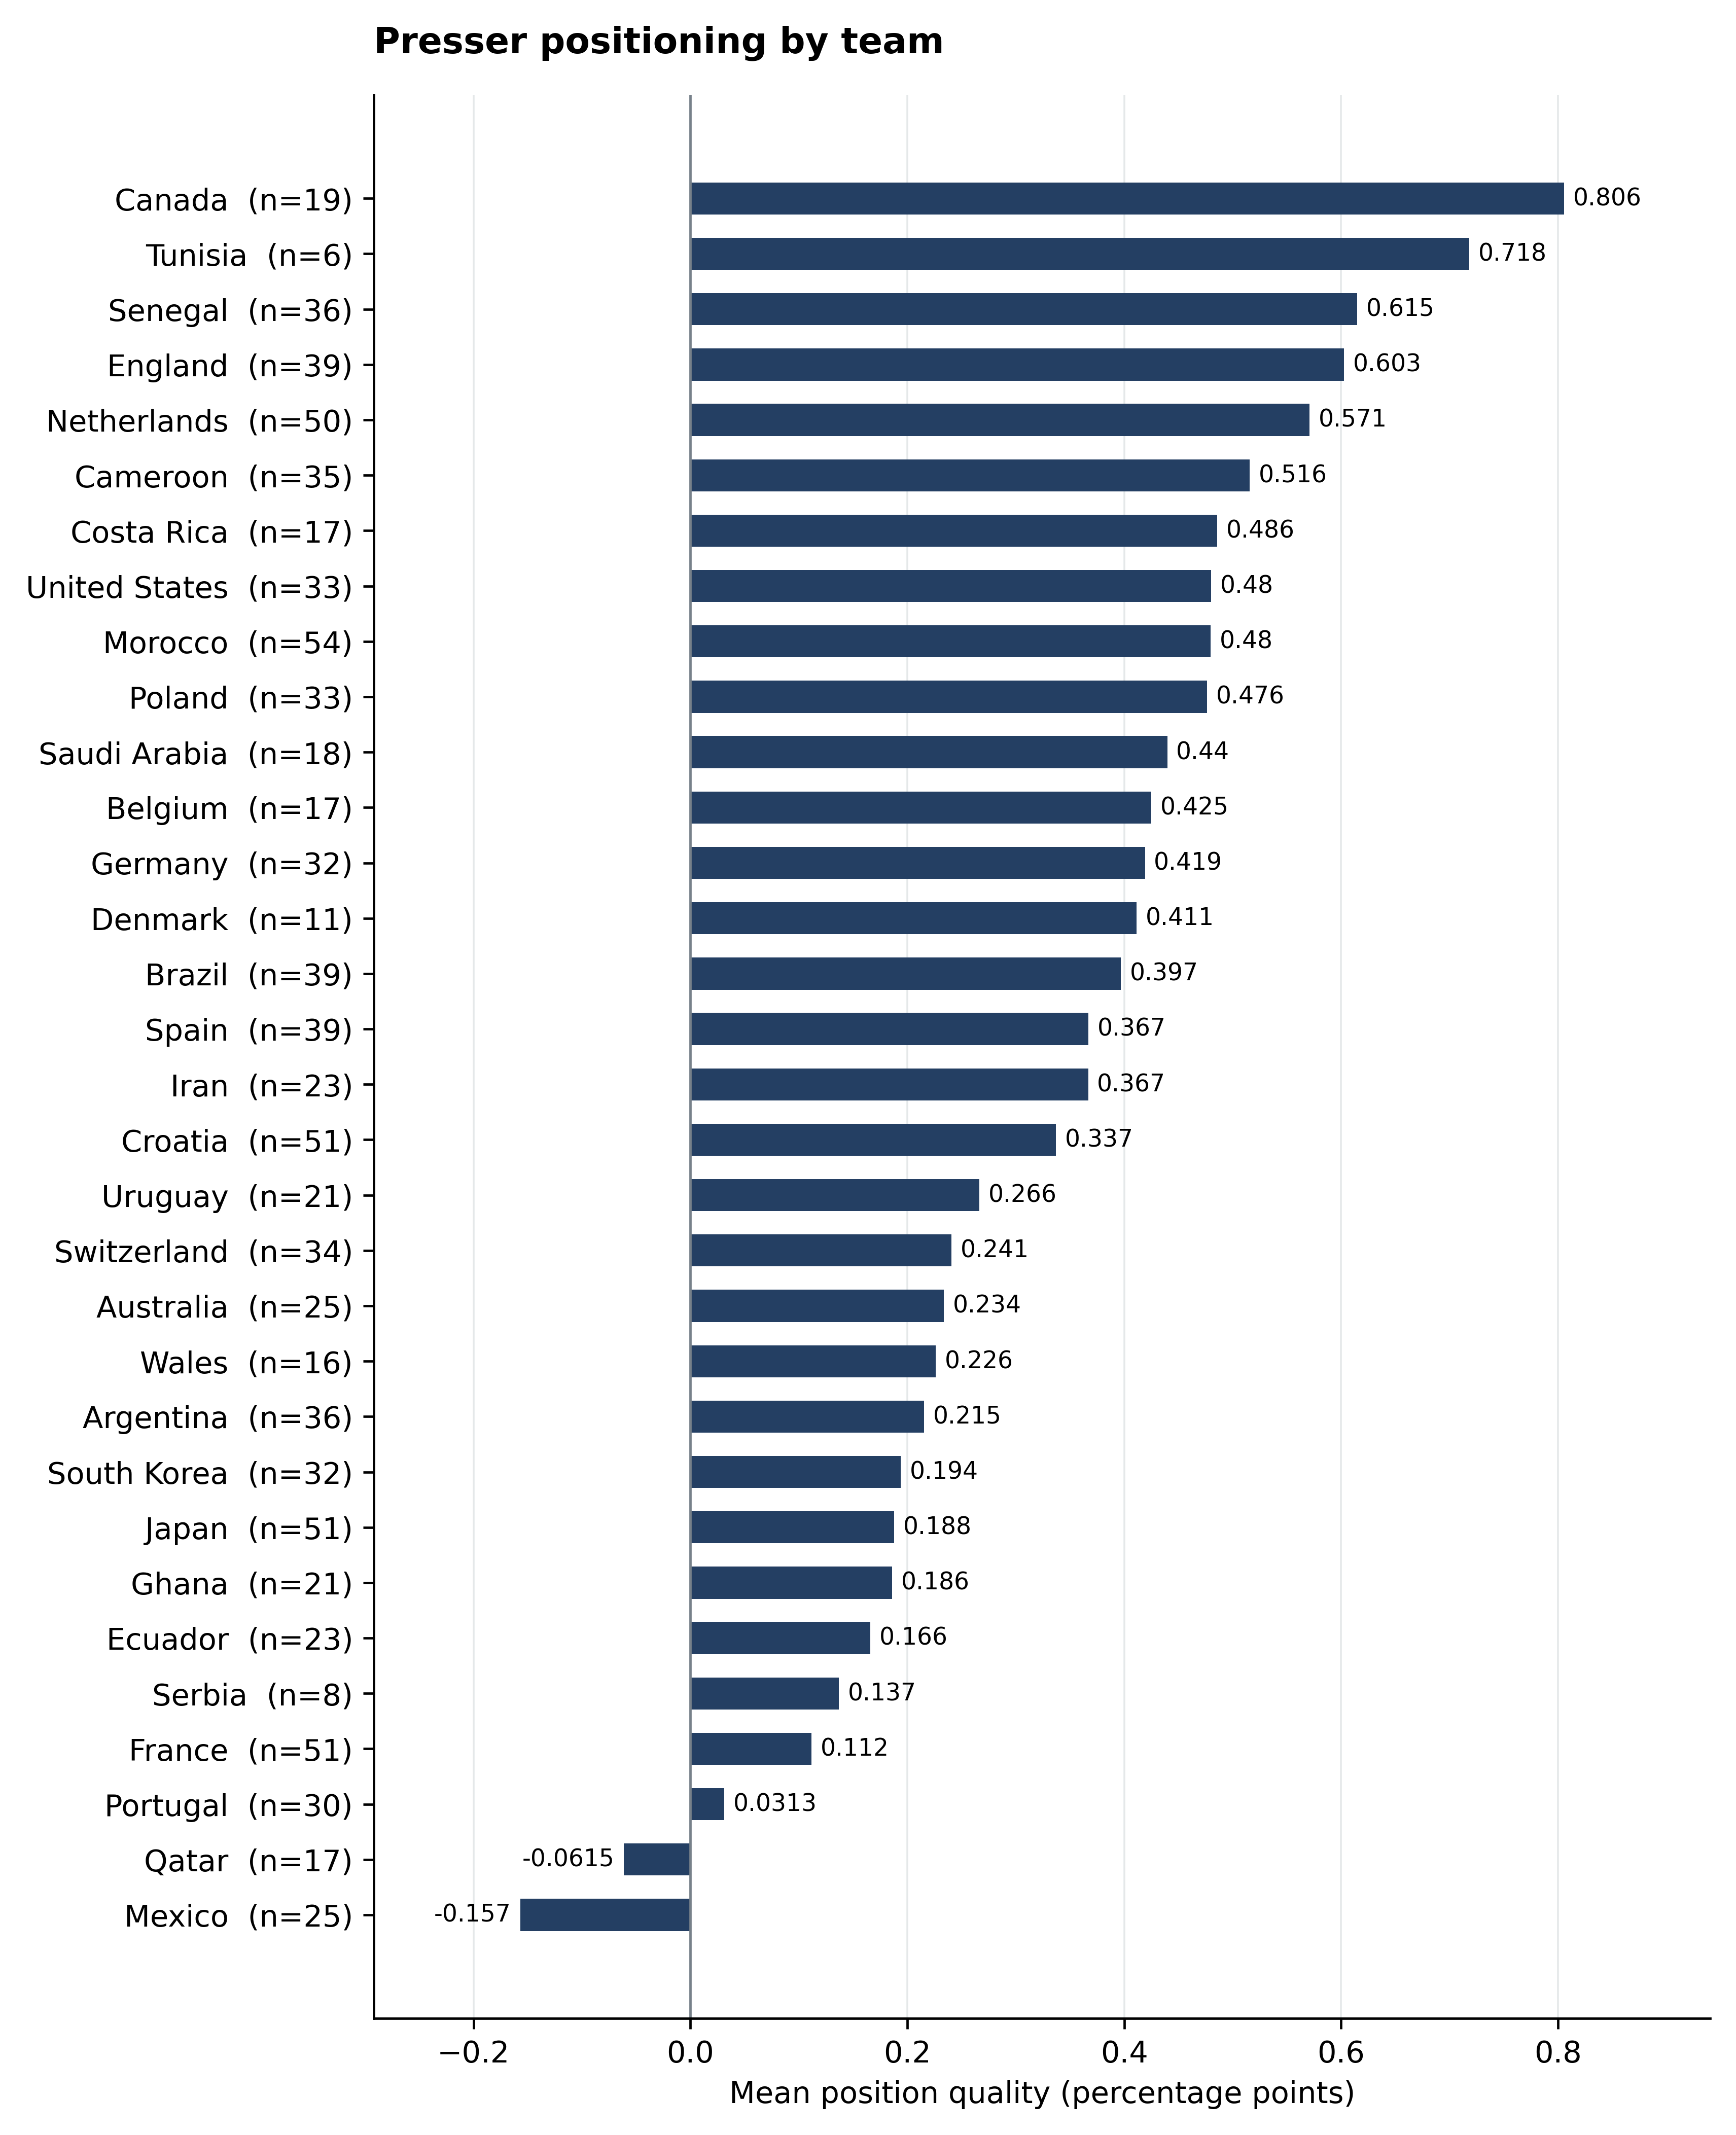

### Presser positioning by player · FIFA World Cup 2022 · all 64 matches

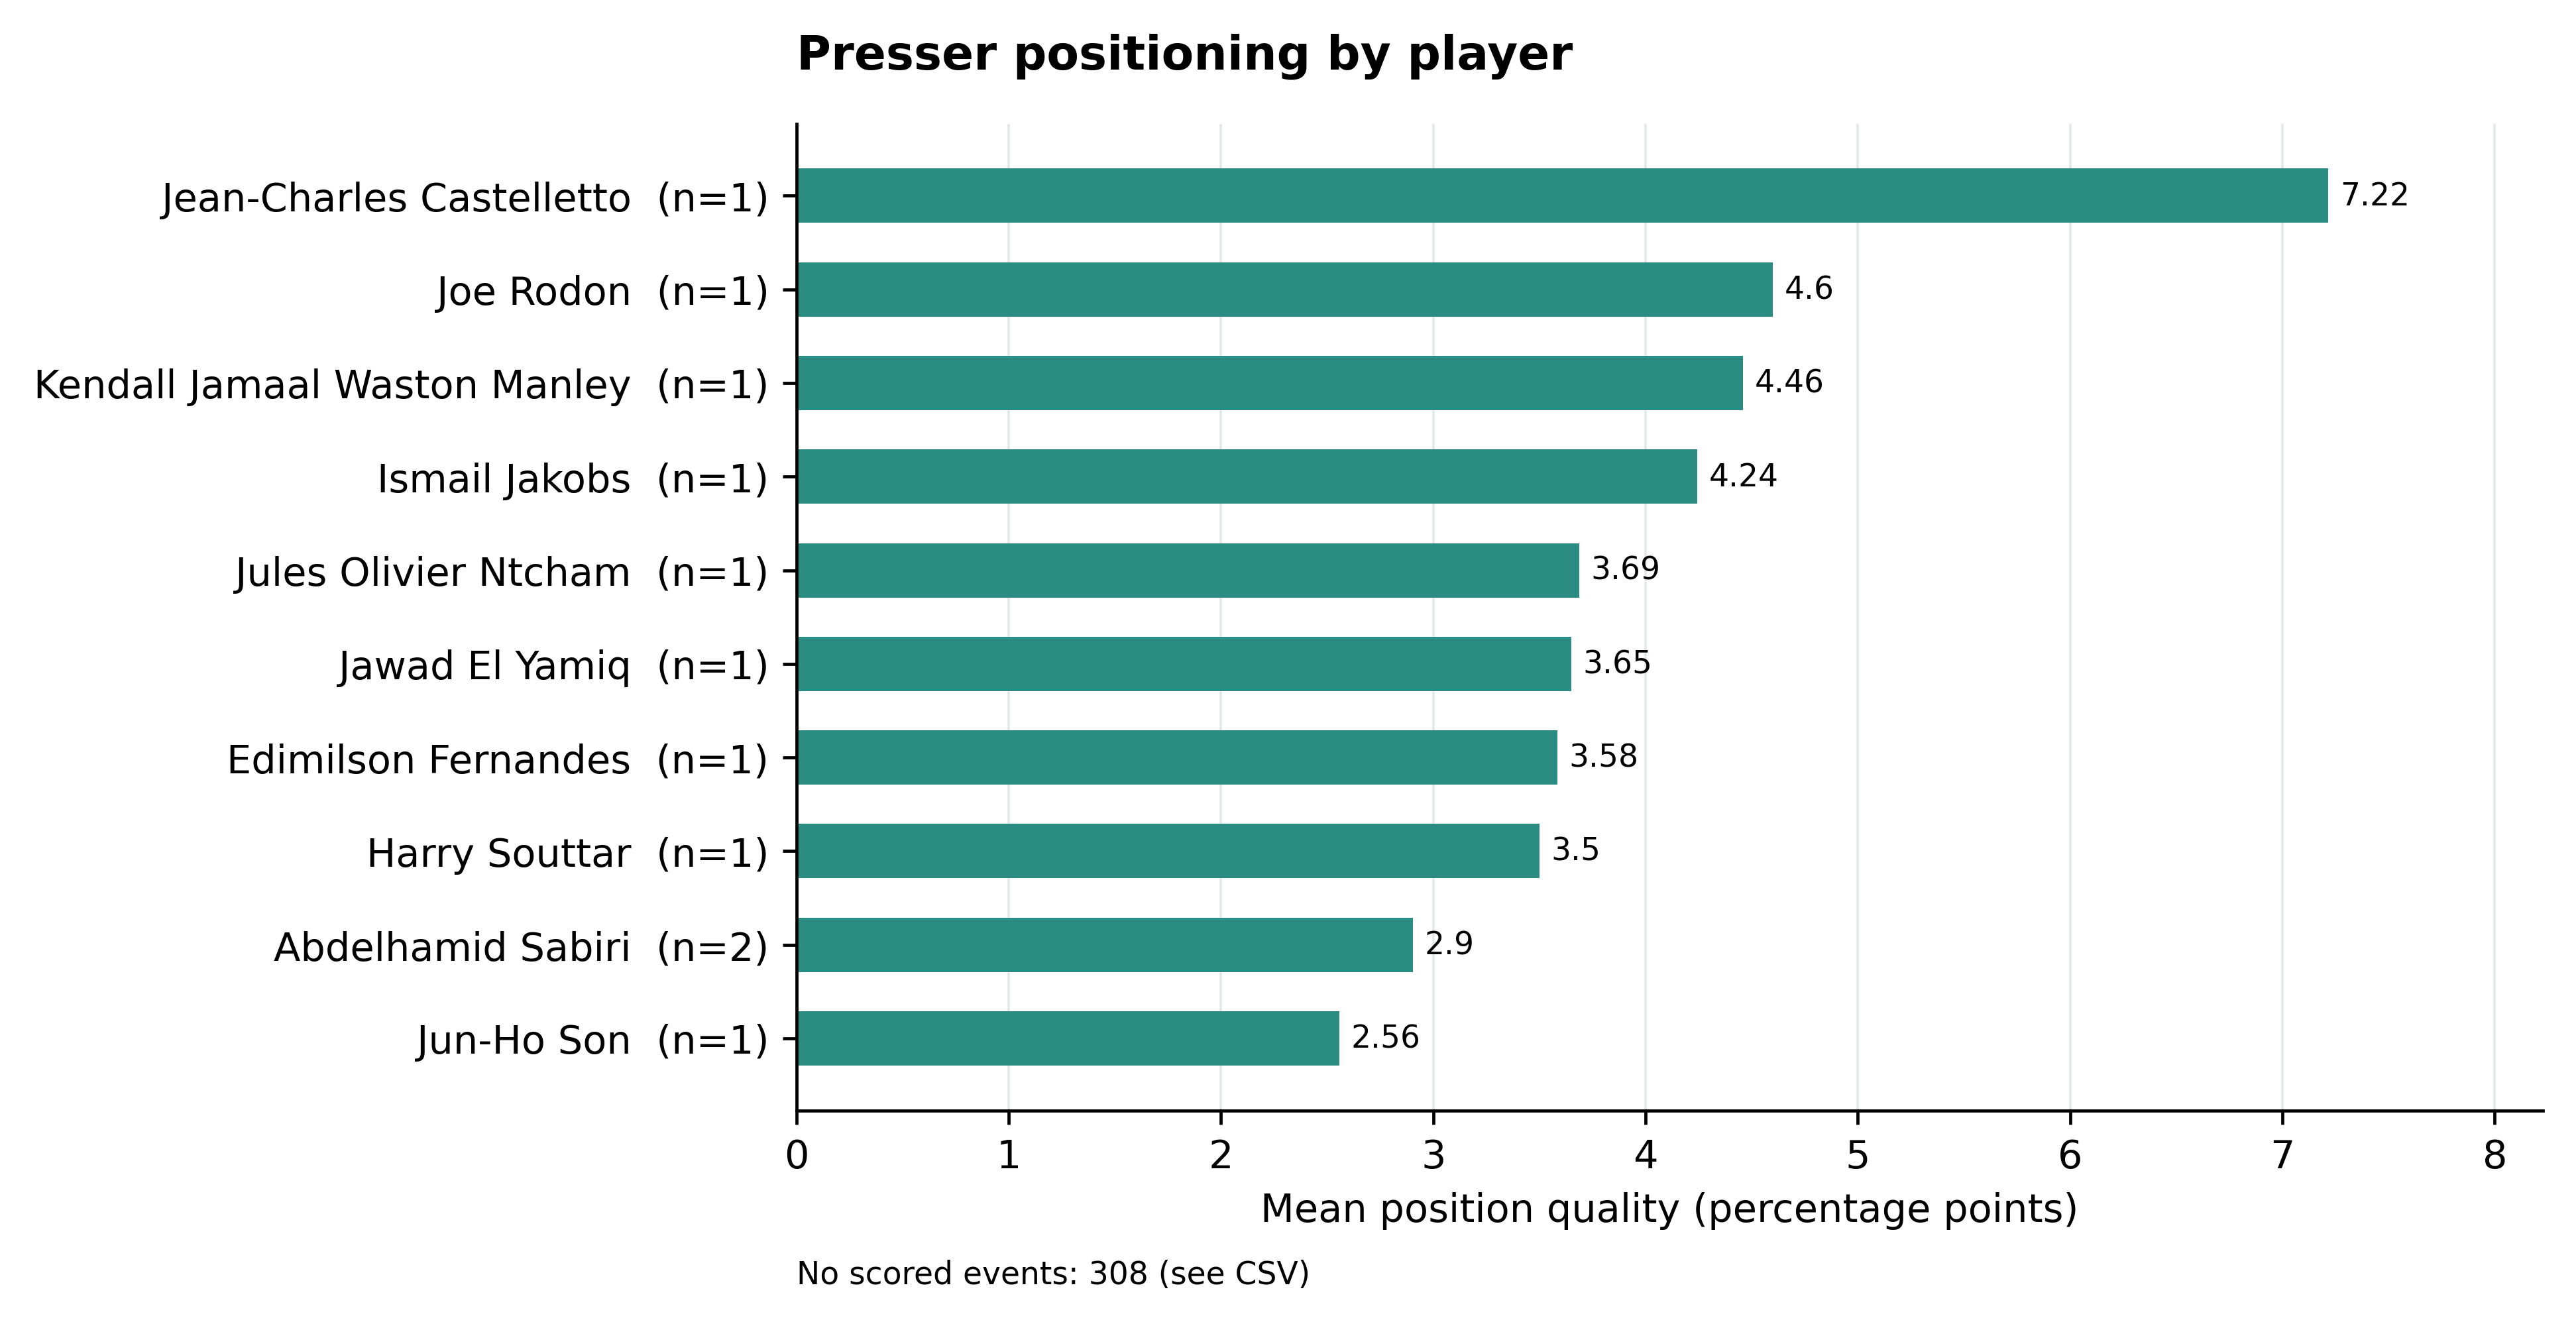

In [8]:
from spn.plotting import RANKINGS, TITLES, generate_plots

plot_dir = sample_dir / "plots"
first = next(iter(fixtures.values()))
tournament = f"{first['competition']['competition_name']} {first['season']['season_name']}"

def show_plots(report, scope):
    for key, item in report["plots"].items():
        caption = f"{TITLES[key]} · {tournament} · {scope}"
        display(Markdown(f"### {caption}"))
        if item["status"] == "skipped":
            print(item["reason"])
        else:
            path = Path(report["output"]) / f"{key}.png"
            display(Image(filename=str(path), width=800, alt=caption), metadata={"alt": caption})

if len(fixtures) == len(catalogue):
    match_scope = f"all {len(fixtures)} matches"
else:
    match_scope = "1 selected match" if len(fixtures) == 1 else f"{len(fixtures)} selected matches"
rankings = generate_plots(plot_dir, input_source=matches_dir, events_dir=events_dir,
                         plots=RANKINGS, overwrite=True)
show_plots(rankings, match_scope)

## Team scatter plots · `spn.plotting`

Each dot represents one team. The first chart compares press value relative to the mean over all scored sequence onsets with xG difference per match. It uses the full selection and excludes shootout attempts.

The second chart compares mean presser positioning (percentage points) with points earned over the same fixtures. In the 2022 World Cup these are the 48 group-stage matches. Only teams with a scored pressure in that stage have a position on the chart.

### Expected press value and expected-goal difference · FIFA World Cup 2022 · all 64 matches

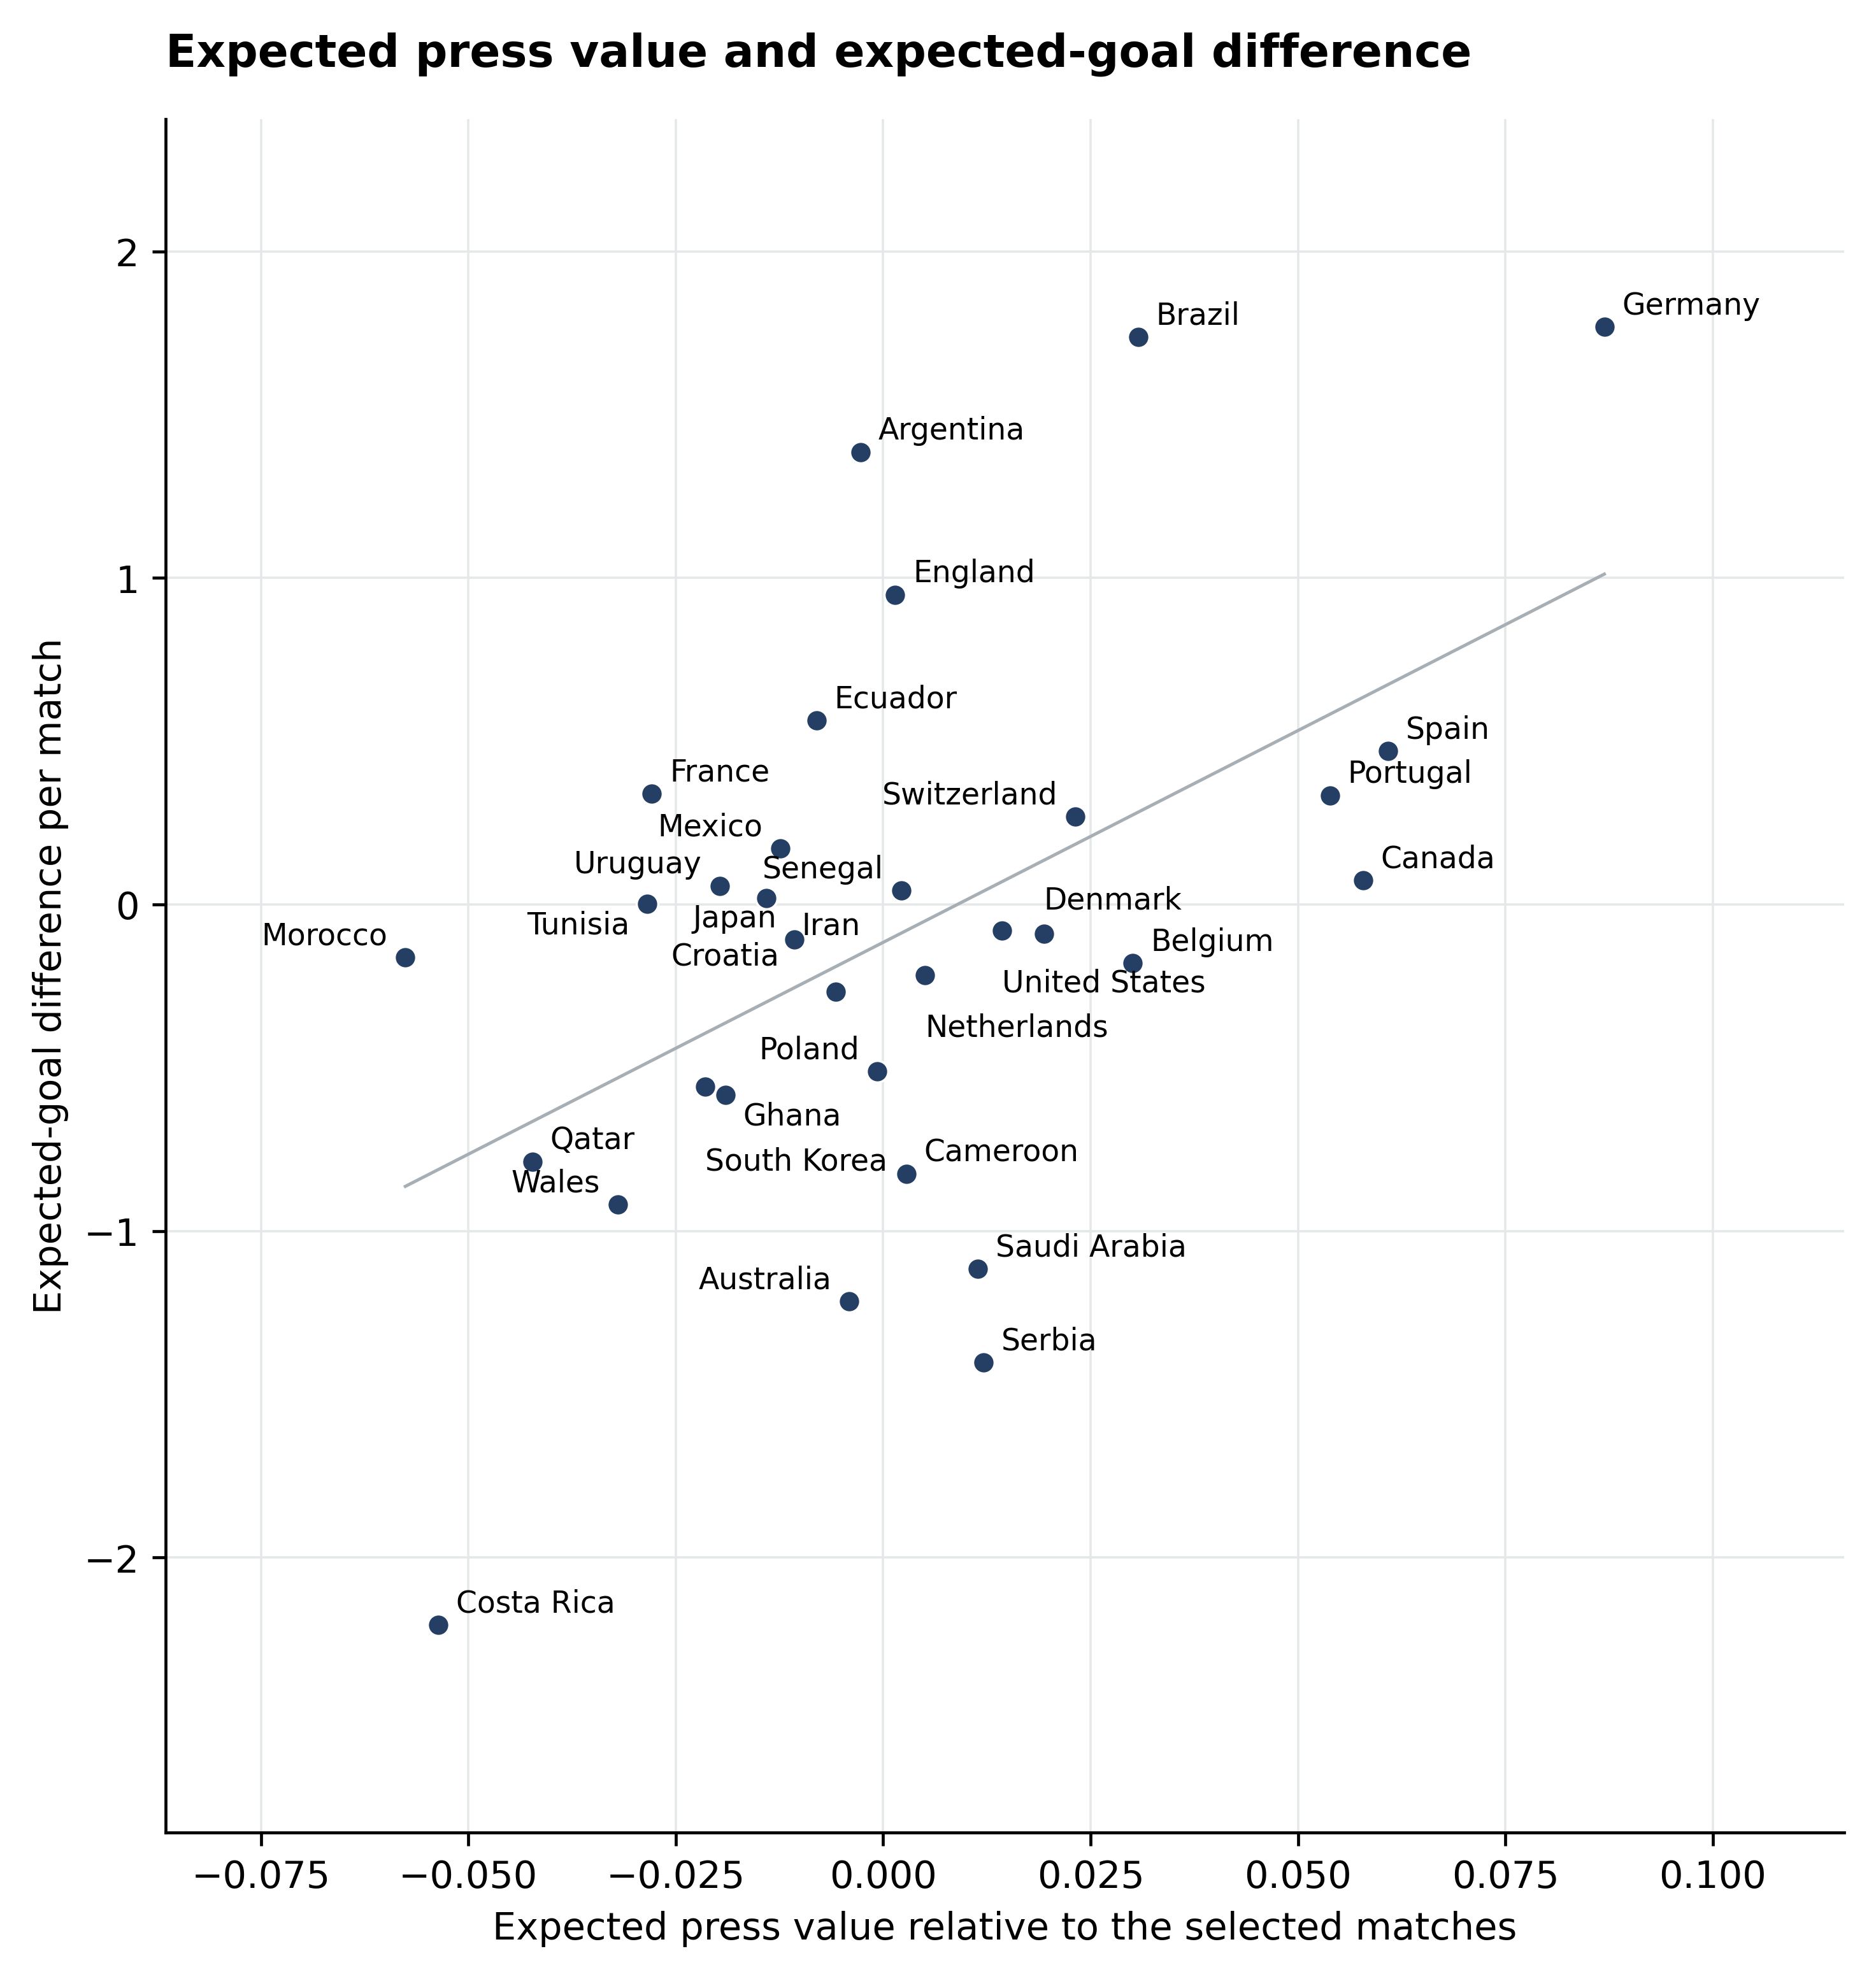

### Presser positioning and competition points · FIFA World Cup 2022 · Group Stage · 48 matches

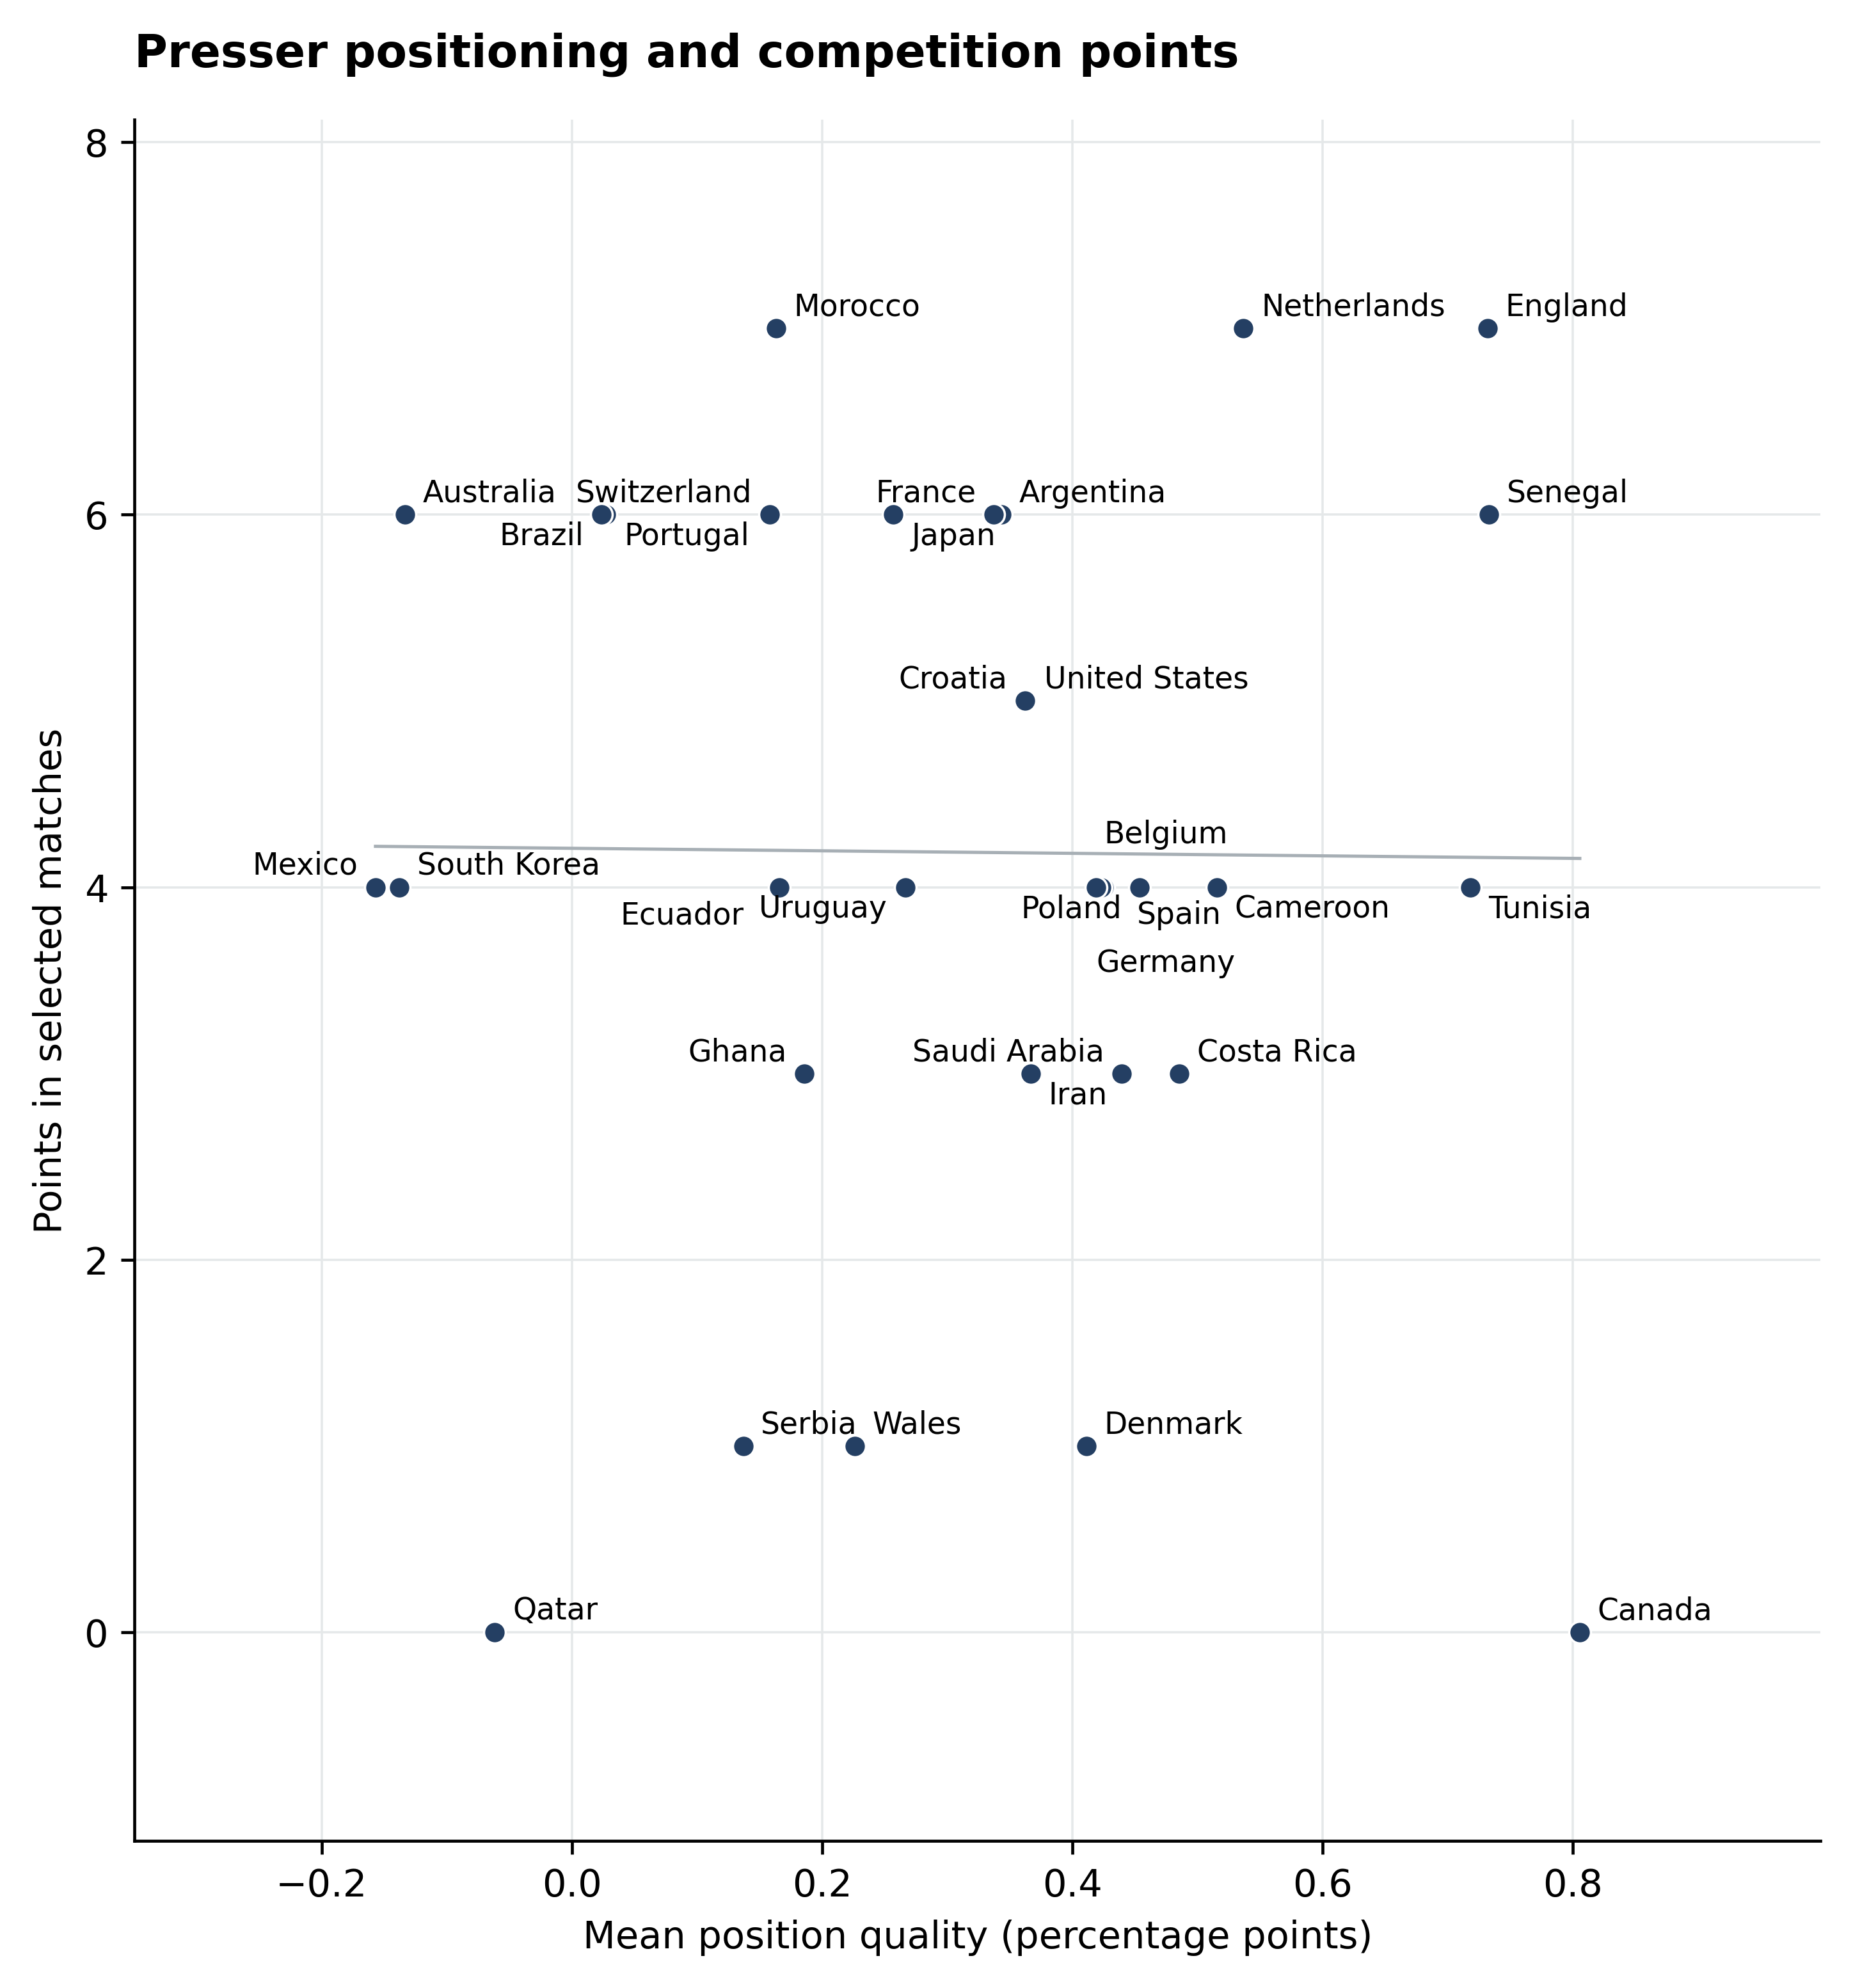

In [9]:
xg_report = generate_plots(
    plot_dir / "value-xgd", input_source=matches_dir, plots=["value-xgd"],
    events_dir=events_dir, overwrite=True,
)
show_plots(xg_report, match_scope)

# Restrict both positioning scores and points to fixtures that award competition points.
stage = fixture_table["stage"]
points_ids = stage.index[stage.str.casefold().isin(["group stage", "league stage", "regular season"])].tolist()
points_file = sample_dir / "selected_matches.json"
points_file.write_text(json.dumps(list(fixtures.values())), encoding="utf-8")

points_report = generate_plots(
    plot_dir / "positioning-points", input_source=matches_dir, plots=["positioning-points"],
    match_ids=points_ids or None, points=points_file, overwrite=True,
)
points_scope = match_scope
if points_ids:
    stages = ", ".join(stage.loc[points_ids].unique())
    count = "1 match" if len(points_ids) == 1 else f"{len(points_ids)} matches"
    points_scope = f"{stages} · {count}"
show_plots(points_report, points_scope)